# ARC-AGI-2 solver — experiment analysis

A program-synthesis solver for ARC-AGI-2: **best-first search over a DSL of grid primitives**,
optionally guided by a **learned prior** that predicts which primitives a task needs.

| Arm | Search order | Prior trained on |
|---|---|---|
| `uniform` | breadth-first (every primitive costs 1) | — |
| `dream` | cost = −log P(primitive \| task) | 30k random DSL programs run on real training inputs |
| `wake` | same | dream data + programs search found on real training tasks |
| `d4_*` | same as above, but programs up to 4 steps instead of 3 | |

**Protocol.** Priors only ever see the *training* split, and never the held-out fifth of it
(`is_holdout`, 1 task in 5 by hash). Ablations run on that held-out fifth; the public
*evaluation* split is reported separately. All arms get the same node budget, so differences
in node counts are differences in search efficiency, not machine speed.

## 1. Setup

In [1]:
import json
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap

from solver.dsl import PRIMITIVES
from solver.features import task_features
from solver.grid import background, load_split
from solver.prior import NAMES, is_holdout

RES = Path("results")
# Result files per arm (see experiments.sh)
TRAIN_FULL = "training_v2_uniform"
EVAL_RUNS = {"uniform d3": "evaluation_v2_uniform", "dream d4": "evaluation_v2_d4_dream"}
ARMS = {
    "uniform": "training_hold_d3_uniform",
    "dream": "training_hold_d3_dream",
    "wake": "training_hold_d3_wake",
    "uniform d4": "training_hold_d4_uniform",
    "dream d4": "training_hold_d4_dream",
}
PRIOR = "models/prior_dream_v2.joblib"
V1 = "training_baseline"  # first DSL version (46 primitives), for comparison

# Reference categorical palette, fixed order; text stays in neutral ink
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
ARM_COLOR = dict(zip(ARMS, SERIES))
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "lines.linewidth": 2,
})
ARC_CMAP = ListedColormap(["#000000", "#0074D9", "#FF4136", "#2ECC40", "#FFDC00",
                           "#AAAAAA", "#F012BE", "#FF851B", "#7FDBFF", "#870C25"])


def load(name):
    return pd.DataFrame(json.loads((RES / f"{name}.json").read_text())["tasks"]).set_index("task")


train_tasks, eval_tasks = load_split("training"), load_split("evaluation")
full = load(TRAIN_FULL)
arms = {a: load(f) for a, f in ARMS.items() if (RES / f"{f}.json").exists()}
evals = {a: load(f) for a, f in EVAL_RUNS.items() if (RES / f"{f}.json").exists()}
print(f"{len(PRIMITIVES)} primitives | training {len(train_tasks)} | evaluation {len(eval_tasks)} | "
      f"held-out {sum(map(is_holdout, train_tasks))} | arms loaded: {list(arms)}")

55 primitives | training 1000 | evaluation 120 | held-out 184 | arms loaded: ['uniform', 'dream', 'wake', 'uniform d4', 'dream d4']


## 2. The data: what kinds of tasks are there?

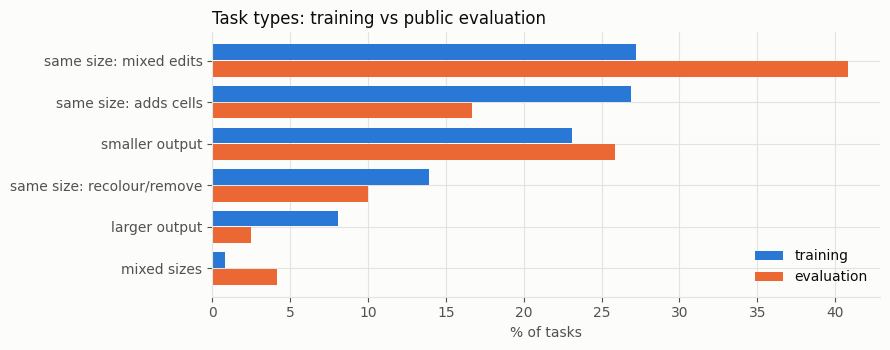

,training,evaluation
same size: mixed edits,27.2,40.8
same size: adds cells,26.9,16.7
smaller output,23.1,25.8
same size: recolour/remove,13.9,10.0
larger output,8.1,2.5
mixed sizes,0.8,4.2


In [2]:
def category(task):
    """Coarse task type from how outputs relate to inputs."""
    pairs = task["train"]
    if all(x.shape == y.shape for x, y in pairs):
        added = np.mean([((x != y) & (x == background(x))).sum() / max((x != y).sum(), 1) for x, y in pairs])
        if added > 0.95:
            return "same size: adds cells"
        if added < 0.05:
            return "same size: recolour/remove"
        return "same size: mixed edits"
    if all(y.size < x.size for x, y in pairs):
        return "smaller output"
    if all(y.size > x.size for x, y in pairs):
        return "larger output"
    return "mixed sizes"


cat_train = pd.Series({t: category(v) for t, v in train_tasks.items()})
cat_eval = pd.Series({t: category(v) for t, v in eval_tasks.items()})
order = cat_train.value_counts().index
share = pd.DataFrame({"training": cat_train.value_counts(normalize=True),
                      "evaluation": cat_eval.value_counts(normalize=True)}).reindex(order).fillna(0) * 100

fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(order))
ax.barh(y - 0.2, share["training"], 0.38, color=SERIES[0], label="training")
ax.barh(y + 0.2, share["evaluation"], 0.38, color=SERIES[1], label="evaluation")
ax.set_yticks(y, order); ax.invert_yaxis(); ax.set_xlabel("% of tasks")
ax.set_title("Task types: training vs public evaluation", loc="left")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()
share.round(1)

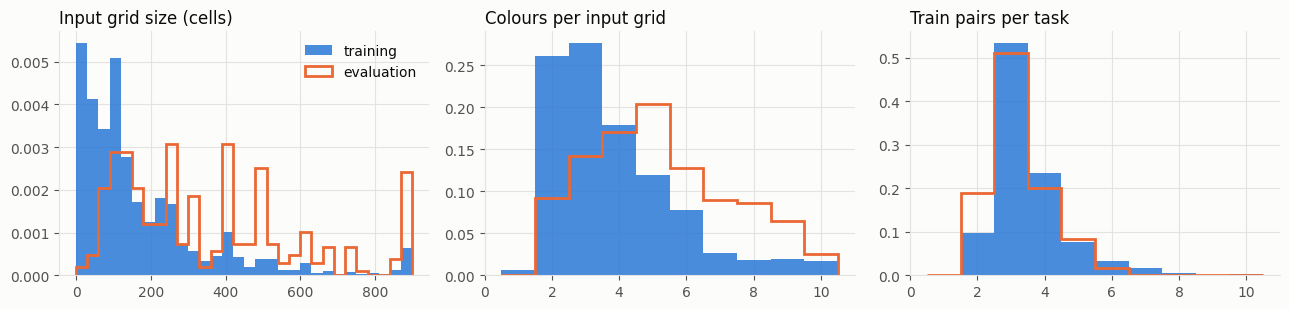

,training median,evaluation median
cells,100.0,299.0
colours,3.0,5.0
pairs,3.0,3.0


In [3]:
def sizes(tasks):
    return pd.DataFrame([{"cells": x.size, "colours": len(np.unique(x)), "pairs": len(t["train"])}
                         for t in tasks.values() for x, _ in t["train"]])

st, se = sizes(train_tasks), sizes(eval_tasks)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, col, bins in zip(axes, ["cells", "colours", "pairs"], [np.linspace(0, 900, 31), np.arange(1, 12) - 0.5, np.arange(1, 12) - 0.5]):
    ax.hist(st[col], bins=bins, density=True, color=SERIES[0], alpha=0.85, label="training")
    ax.hist(se[col], bins=bins, density=True, histtype="step", color=SERIES[1], linewidth=2, label="evaluation")
    ax.set_title({"cells": "Input grid size (cells)", "colours": "Colours per input grid",
                  "pairs": "Train pairs per task"}[col], loc="left")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
pd.DataFrame({"training median": st.median(), "evaluation median": se.median()})

The evaluation split skews toward larger grids and "mixed edit" tasks — exactly the kind that a
fixed library of whole-grid transformations struggles with.

## 3. Coverage: what does the DSL solve?

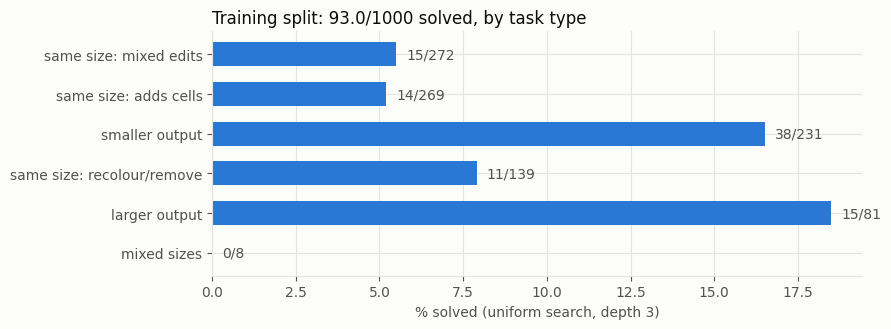

,tasks,solved,rate %
same size: mixed edits,272,15,5.5
same size: adds cells,269,14,5.2
smaller output,231,38,16.5
same size: recolour/remove,139,11,7.9
larger output,81,15,18.5
mixed sizes,8,0,0.0


In [4]:
full["category"] = cat_train
full["solved"] = full["score"] > 0
by_cat = full.groupby("category").agg(tasks=("solved", "size"), solved=("solved", "sum")).reindex(order)
by_cat["rate %"] = (100 * by_cat["solved"] / by_cat["tasks"]).round(1)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(order, by_cat["rate %"], color=SERIES[0], height=0.6)
for i, (r, s, n) in enumerate(zip(by_cat["rate %"], by_cat["solved"], by_cat["tasks"])):
    ax.text(r + 0.3, i, f"{s}/{n}", va="center", color=INK2)
ax.invert_yaxis(); ax.set_xlabel("% solved (uniform search, depth 3)")
ax.set_title(f"Training split: {full['score'].sum():.1f}/{len(full)} solved, by task type", loc="left")
plt.tight_layout(); plt.show()
by_cat

In [5]:
if (RES / f"{V1}.json").exists():
    v1 = load(V1)
    both = pd.DataFrame({"v1": v1["score"] > 0, "v2": full["solved"]}).dropna()
    print(f"DSL v1 ({V1}): {both['v1'].sum()} solved   DSL v2: {both['v2'].sum()} solved")
    print(f"  gained: {(~both['v1'] & both['v2']).sum()}   lost: {(both['v1'] & ~both['v2']).sum()}")
    lost = both.index[both["v1"] & ~both["v2"]]
    if len(lost):
        print("  lost (programs from v1):", {t: v1.loc[t, "programs"][0] for t in lost})

DSL v1 (training_baseline): 75 solved   DSL v2: 93 solved
  gained: 19   lost: 1
  lost (programs from v1): {'d19f7514': 'rot90 > logic_or > rot270'}


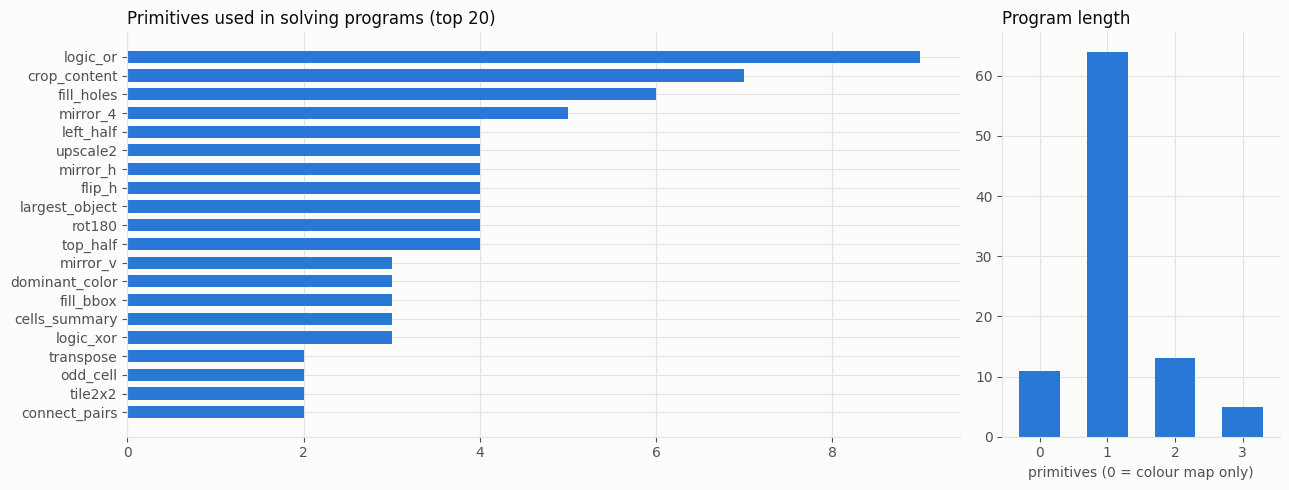

40 of 55 primitives appear in at least one solution; never used: ['antitranspose', 'downscale2', 'downscale3', 'gravity_left', 'gravity_right', 'largest_multicolor_object', 'logic_and', 'logic_nor', 'rays_h', 'rays_v', 'right_half', 'rot270', 'self_kron', 'symmetrize_diag', 'tile3x3']


In [6]:
solved = full[full["solved"]]
prims = Counter(p for prog in solved["programs"] for p in prog[0].split(" > ") if p != "identity")
lengths = solved["programs"].map(lambda ps: 0 if ps[0] == "identity" else len(ps[0].split(" > ")))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [3, 1]})
top = pd.Series(prims).sort_values().tail(20)
axes[0].barh(top.index, top.values, color=SERIES[0], height=0.65)
axes[0].set_title("Primitives used in solving programs (top 20)", loc="left")
lengths.value_counts().sort_index().plot.bar(ax=axes[1], color=SERIES[0], width=0.6, rot=0)
axes[1].set(title="Program length", xlabel="primitives (0 = colour map only)")
axes[1].title.set_ha("left"); axes[1].title.set_x(0)
plt.tight_layout(); plt.show()
print(f"{len(prims)} of {len(PRIMITIVES)} primitives appear in at least one solution; never used:",
      sorted(set(PRIMITIVES) - set(prims)))

## 4. Does the learned prior make search more efficient?

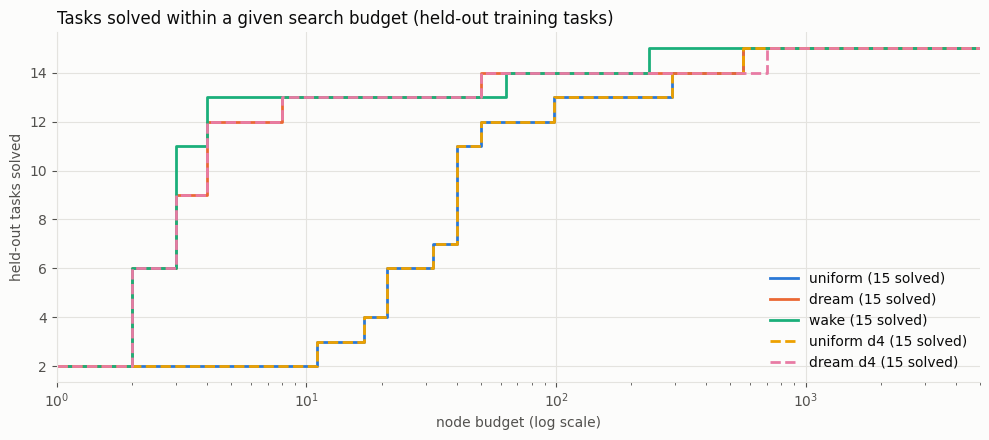

In [7]:
BUDGETS = np.unique(np.logspace(0, np.log10(5000), 40).astype(int))
fig, ax = plt.subplots(figsize=(10, 4.5))
for arm, df in arms.items():
    hits = df.loc[df["score"] > 0, "first_hit"].to_numpy()
    curve = [(hits <= b).sum() for b in BUDGETS]
    ax.step(BUDGETS, curve, where="post", color=ARM_COLOR[arm], ls="--" if "d4" in arm else "-",
            label=f"{arm} ({curve[-1]} solved)")
ax.set_xscale("log"); ax.set_xlim(1, 5000)
ax.legend(frameon=False, loc="lower right")
ax.set(xlabel="node budget (log scale)", ylabel="held-out tasks solved")
ax.set_title("Tasks solved within a given search budget (held-out training tasks)", loc="left")
plt.tight_layout(); plt.show()

In [8]:
def summary(df):
    s = df[df["score"] > 0]
    return {"solved": s.shape[0], "score": df["score"].sum(), "@100": (s["first_hit"] <= 100).sum(),
            "@1000": (s["first_hit"] <= 1000).sum(), "median nodes": s["first_hit"].median(),
            "false positives": int((df["fit_train"] & (df["score"] == 0)).sum()),
            "median seconds": df["seconds"].median()}

table = pd.DataFrame({a: summary(df) for a, df in arms.items()}).T
table

,solved,score,@100,@1000,median nodes,false positives,median seconds
uniform,15.0,15.0,13.0,15.0,34.0,5.0,9.265
dream,15.0,15.0,14.0,15.0,3.0,5.0,8.910
wake,15.0,15.0,14.0,15.0,3.0,5.0,8.470
uniform d4,15.0,15.0,13.0,15.0,34.0,5.0,58.740
dream d4,15.0,15.0,14.0,15.0,3.0,5.0,32.125


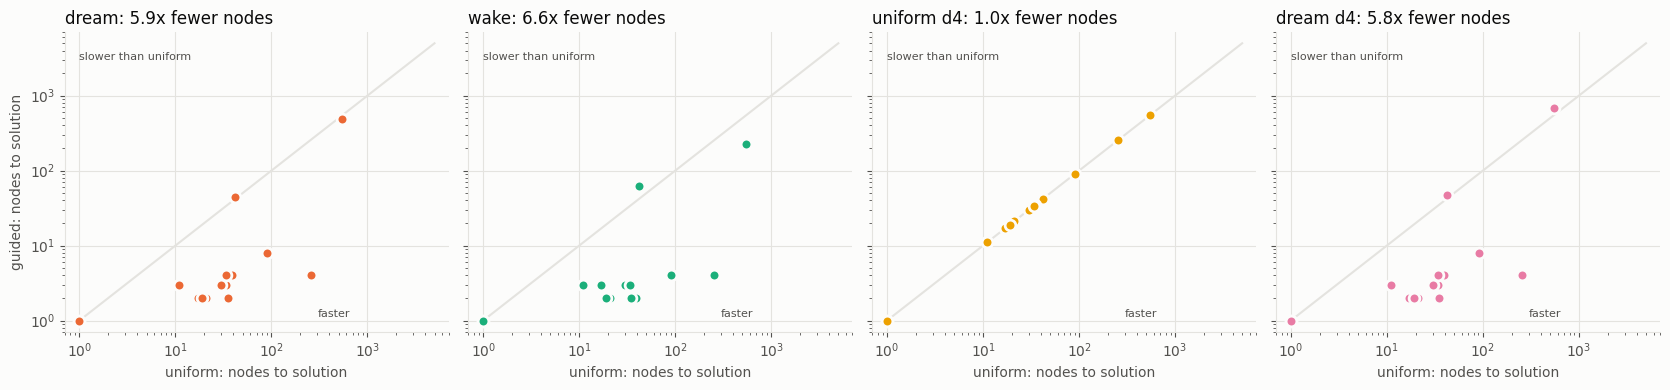

In [9]:
base = arms["uniform"]
fig, axes = plt.subplots(1, len(arms) - 1, figsize=(4.2 * (len(arms) - 1), 4), sharey=True)
for ax, (arm, df) in zip(np.atleast_1d(axes), list(arms.items())[1:]):
    common = base.index[(base["score"] > 0) & (df["score"] > 0)]
    x, y = base.loc[common, "first_hit"], df.loc[common, "first_hit"]
    ax.plot([1, 5000], [1, 5000], color=GRID, lw=1.5, zorder=0)
    ax.scatter(x, y, s=60, color=ARM_COLOR[arm], edgecolor="#fcfcfb", linewidth=2, zorder=2)
    gm = np.exp(np.mean(np.log(x / y))) if len(common) else float("nan")
    ax.set(xscale="log", yscale="log", xlim=(0.7, 7000), ylim=(0.7, 7000), xlabel="uniform: nodes to solution")
    ax.set_title(f"{arm}: {gm:.1f}x fewer nodes", loc="left")
    ax.text(1, 3000, "slower than uniform", color=INK2, fontsize=8)
    ax.text(300, 1.1, "faster", color=INK2, fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("guided: nodes to solution")
plt.tight_layout(); plt.show()

In [10]:
ids = sorted(set().union(*(df.index[df["score"] > 0] for df in arms.values())))
nodes = pd.DataFrame({a: df.loc[ids, "first_hit"].where(df.loc[ids, "score"] > 0) for a, df in arms.items()})
nodes["program"] = [next(df.loc[t, "programs"][0] for df in arms.values() if df.loc[t, "score"] > 0) for t in ids]
nodes.fillna("-")

,uniform,dream,wake,uniform d4,dream d4,program
task,,,,,,
0c786b71,91.0,8.0,4.0,91.0,8.0,rot180 > mirror_4
22168020,39.0,4.0,2.0,39.0,4.0,connect_pairs
2dc579da,42.0,44.0,62.0,42.0,47.0,odd_cell
31d5ba1a,34.0,3.0,3.0,34.0,3.0,logic_xor
4258a5f9,35.0,2.0,2.0,35.0,2.0,halo8
642d658d,256.0,4.0,4.0,256.0,4.0,largest_object > dominant_color
6fa7a44f,21.0,2.0,2.0,21.0,2.0,mirror_v
9172f3a0,17.0,2.0,3.0,17.0,2.0,upscale3
9565186b,1.0,1.0,1.0,1.0,1.0,identity


## 5. Inside the prior: does it rank the right primitives first?

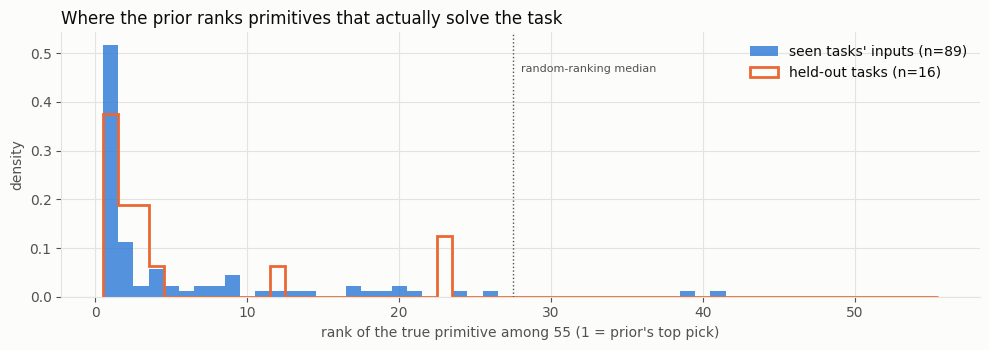

,count,mean,50%,top5
holdout,,,,
False,89.0,5.460674,1.0,0.73
True,16.0,5.187500,2.0,0.81


In [11]:
# joblib unpickles: this is the model trained locally by solver.prior
prior = joblib.load(PRIOR)
rows = []
for t, r in full[full["solved"]].iterrows():
    used = [p for p in r["programs"][0].split(" > ") if p != "identity"]
    if not used:
        continue
    p = prior.predict_proba(np.nan_to_num(task_features(train_tasks[t]["train"]))[None])[0]
    ranks = (-p).argsort().argsort() + 1  # 1 = most probable primitive
    rows += [{"task": t, "primitive": u, "rank": ranks[NAMES.index(u)], "holdout": is_holdout(t)} for u in used]
ranks = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.arange(1, len(NAMES) + 2) - 0.5
for i, (hold, label) in enumerate([(False, "seen tasks' inputs"), (True, "held-out tasks")]):
    sub = ranks[ranks["holdout"] == hold]["rank"]
    ax.hist(sub, bins=bins, density=True, color=SERIES[i], alpha=0.8 if i == 0 else 1,
            histtype="bar" if i == 0 else "step", linewidth=2, label=f"{label} (n={len(sub)})")
ax.axvline(len(NAMES) / 2, color=INK2, ls=":", lw=1)
ax.text(len(NAMES) / 2 + 0.5, ax.get_ylim()[1] * 0.85, "random-ranking median", color=INK2, fontsize=8)
ax.set(xlabel=f"rank of the true primitive among {len(NAMES)} (1 = prior's top pick)", ylabel="density")
ax.set_title("Where the prior ranks primitives that actually solve the task", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
ranks.groupby("holdout")["rank"].describe()[["count", "mean", "50%"]].assign(
    top5=ranks.groupby("holdout")["rank"].apply(lambda r: (r <= 5).mean()).round(2))

## 6. Failure modes

In [12]:
fp = full[full["fit_train"] & (full["score"] == 0)]
print(f"{len(fp)} false positives: a program fit every train pair but got the test output wrong")
fp[["programs", "first_hit"]].assign(category=cat_train)

14 false positives: a program fit every train pair but got the test output wrong


,programs,first_hit,category
task,,,
1a2e2828,"[mirror_h > overlay_halves > dominant_color, m...",3707.0,smaller output
3194b014,"[smallest_object > upscale3, dominant_color > ...",244.0,smaller output
39a8645d,[color_by_size_rank > smallest_object],884.0,smaller output
47c1f68c,[odd_cell > mirror_4],738.0,smaller output
5582e5ca,"[dominant_color > upscale3, bottom_half > righ...",657.0,same size: recolour/remove
9ba4a9aa,"[right_half > largest_object, rot90 > top_half...",422.0,smaller output
a61f2674,[halo8 > color_by_size_rank],655.0,same size: recolour/remove
a79310a0,[flip_v > halo8 > gravity_up],1812.0,same size: mixed edits
aabf363d,"[identity, remove_noise]",1.0,same size: recolour/remove


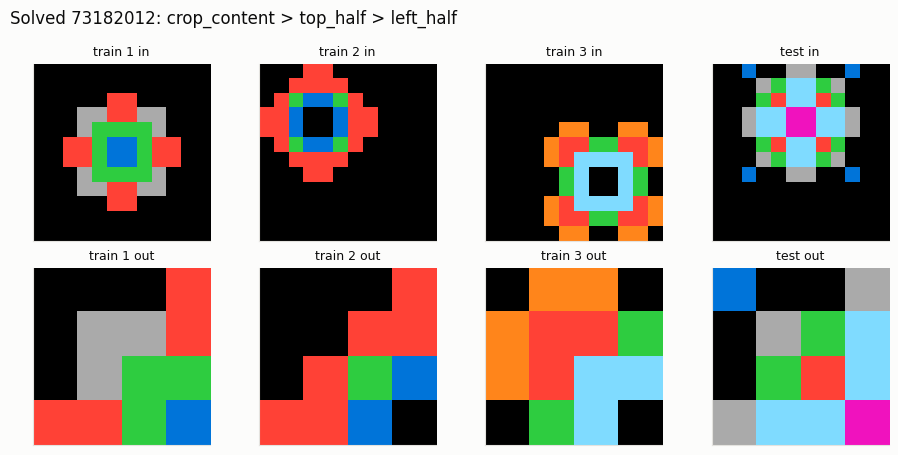

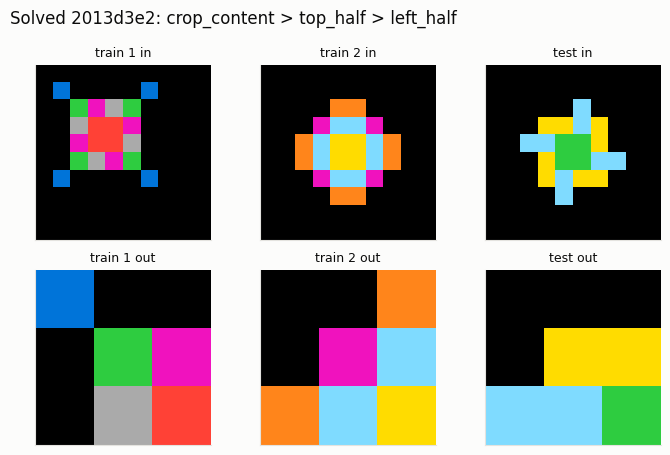

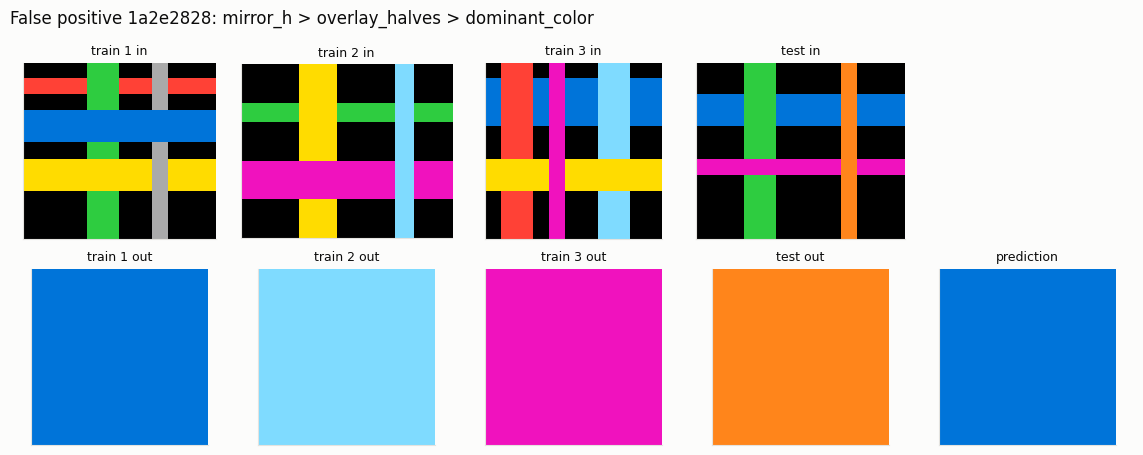

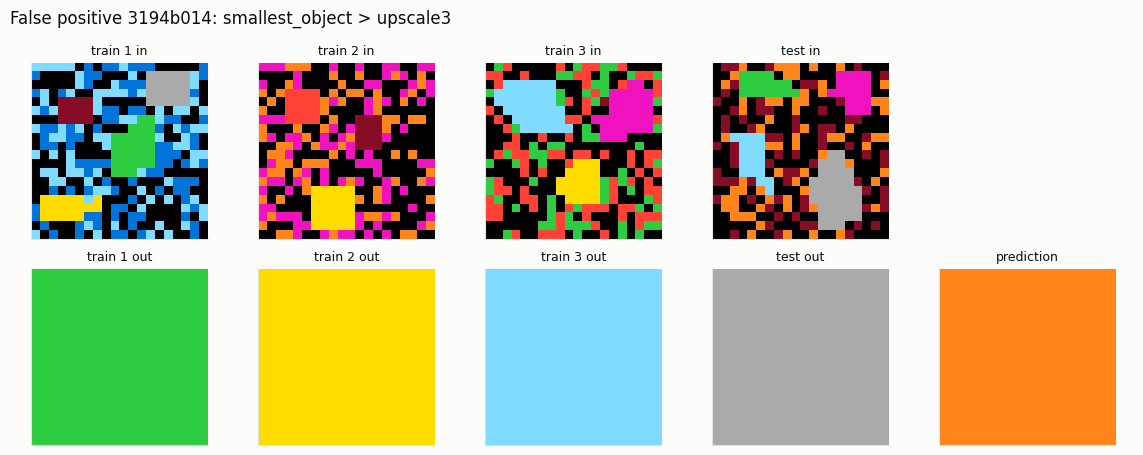

In [13]:
def show(task_id, tasks, title, pred=None):
    task = tasks[task_id]
    pairs = task["train"][:3] + [(task["test"][0][0], task["test"][0][1])]
    cols = len(pairs) + (pred is not None)
    fig, axes = plt.subplots(2, cols, figsize=(2.3 * cols, 4.6))
    for j, (x, y) in enumerate(pairs):
        for i, g in enumerate((x, y)):
            ax = axes[i, j]
            ax.imshow(g, cmap=ARC_CMAP, vmin=0, vmax=9)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            ax.set_title(("test " if j == len(pairs) - 1 else f"train {j + 1} ") + ("in" if i == 0 else "out"), fontsize=9)
    if pred is not None:
        axes[0, -1].axis("off")
        axes[1, -1].imshow(pred, cmap=ARC_CMAP, vmin=0, vmax=9); axes[1, -1].set_title("prediction", fontsize=9)
        axes[1, -1].set_xticks([]); axes[1, -1].set_yticks([]); axes[1, -1].grid(False)
    fig.suptitle(title, x=0.01, ha="left")
    plt.tight_layout(); plt.show()


from solver.search import solve
examples = full[full["solved"]].sort_values("first_hit", ascending=False)
for t in examples.index[:2]:
    show(t, train_tasks, f"Solved {t}: {examples.loc[t, 'programs'][0]}")
for t in fp.index[:2]:
    res = solve(train_tasks[t], max_nodes=5000)
    show(t, train_tasks, f"False positive {t}: {fp.loc[t, 'programs'][0]}", pred=res.attempts[0][0])

## 7. Public evaluation split

            score  fit train  median seconds
uniform d3    0.0        0.0          13.075
dream d4      0.0        0.0          45.565

Evaluation task types (all unsolved unless listed above):
same size: mixed edits        49
smaller output                31
same size: adds cells         20
same size: recolour/remove    12
mixed sizes                    5
larger output                  3
Name: count, dtype: int64


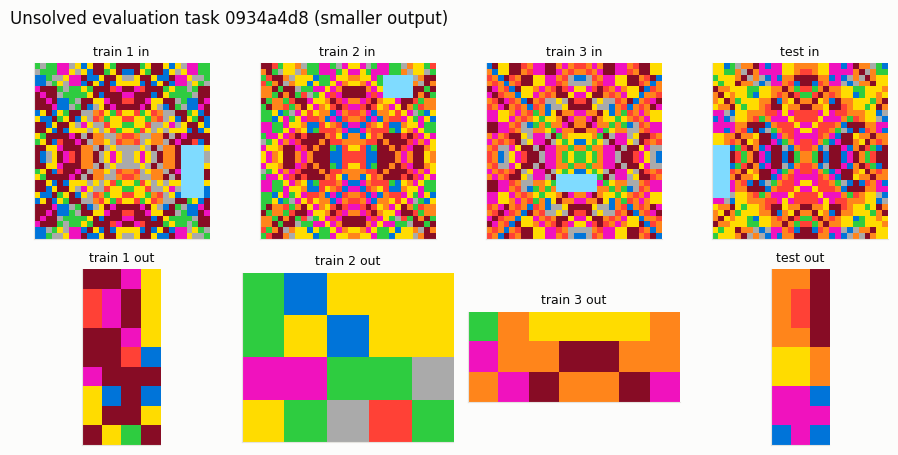

In [14]:
ev = pd.DataFrame({a: {"score": df["score"].sum(), "fit train": int(df["fit_train"].sum()),
                       "median seconds": df["seconds"].median()} for a, df in evals.items()}).T
print(ev)
unsolved = cat_eval.value_counts()
print("\nEvaluation task types (all unsolved unless listed above):"); print(unsolved)
show(cat_eval.index[0], eval_tasks, f"Unsolved evaluation task {cat_eval.index[0]} ({cat_eval.iloc[0]})")

## 8. Findings

**1. The learned prior makes search ~6x more efficient, with zero task-specific supervision.**
On the 184 held-out training tasks, the median solution is found after **3 nodes instead of 34**
(geometric-mean speed-up 5.9x for the dream prior, 6.6x with wake data). The prior was trained only on
random DSL programs executed on *other* tasks' input grids — it never saw a held-out task or a
human-written solution. Inside the prior, the primitive that actually solves a task has median rank
**2 of 55** on held-out tasks, and is in the top 5 for 81% of them (random ranking: median ~28).

**2. ...but it solves exactly the same tasks. The bottleneck is the DSL, not the search.**
Every arm solves the same 15/184 held-out tasks. With 55 primitives, every program the DSL can express
that fits a held-out task is found within ~550 nodes even by blind breadth-first search, far below the
5,000-node budget. A better search order cannot find programs that do not exist.

**3. Going deeper does not help either.** Allowing 4-step programs found no new solutions. What the
prior *does* buy at depth 4 is wall-clock time: median 32 s vs 59 s per task, because guided search
reaches its solutions before the frontier explodes. This is where a prior would matter if the DSL
had solutions at depth 4+.

**4. Growing the DSL is what moved the score.** Adding 9 primitives (drawing, cell summaries, odd-one-out)
and object-level recolouring took the training split from **74.5 to 93 / 1000** (+19 tasks, 1 lost to the
larger branching factor). Gains are uneven: "smaller output" (16.5%) and "larger output" (18.5%) tasks
are solved 3x as often as same-size edit tasks (~5–8%), which need *local, object-conditional* rules
that whole-grid primitives cannot express. 15 of 55 primitives are never used in any solution.

**5. Coincidental fits are a real failure mode.** 14 training tasks have a program that fits every train
pair yet fails the test (5 of them in the held-out set). Most are "smaller output" tasks where the output
is tiny (often 1x1 or a small crop), so many unrelated programs can match a handful of examples by
chance. Shortest-program-first (Occam) ordering does not prevent this.

**6. ARC-AGI-2 evaluation: 0 / 120 for every configuration.** Evaluation grids are 3x larger (median 299
vs 100 cells), use more colours (5 vs 3), and are dominated by mixed same-size edits (41%) — the category
this DSL handles worst. This matches ARC-AGI-2's design goal of resisting brute-force program search.

### What this suggests next
- **Expressiveness over search:** primitives that are *parameterised by the examples* (like the
  object-recolour fit) generalise better than more fixed transformations. Object-wise "apply f to each
  object" combinators are the obvious next step.
- **Verification beyond the train pairs:** penalise programs whose output is trivially small or that
  ignore most of the input, to reduce coincidental fits.
- **A learned model for what the DSL cannot express:** LLM test-time training on the GPU, combined with
  the DSL (DSL answers when a program fits; LLM otherwise).